# ReLAC — reproduce all results, tables and figures

Companion notebook of the article *ReLAC: Measuring and Eliminating the Leakage of Revoked Access in Learned Access Control for Cloud Environments*.

**What it runs.** For each train–test split of three public benchmark families (Amazon Employee Access: 5-fold CV × 3 seeds; five HP Labs RBAC benchmarks × 3 seeds; 8 DLBAC synthetic ABAC datasets × 4 operations), a gradient-boosting access-control model is trained, an administrator revocation covering 1%, 5%, 10% or 20% of granted access is simulated, and five remedies are evaluated: stale model, full retraining, weighted retraining, warm-start fine-tuning and an exact deny overlay.

**Data.** Downloaded from the original repositories at fixed commits and verified by SHA-256 (22 files): `dlbac/DlbacAlpha` @ `261df3ea` (Amazon data in DLBAC format, synthetic datasets) and `RoleMining/ConstrainedRM` @ `7a8ecec5` (MIT; HP Labs RBAC).

**Outputs.** `results/summary.json` and `results/paper_numbers.txt` (every number of the article), `results/tables/` (Supplementary Tables S1–S2), `results/figures/fig2–fig6` (PNG and PDF; Fig. 1, the architecture, is a separate diagram) and `revocation_results.zip` with all of them.

**How to run.** `Runtime → Run all` (CPU only, about 30–40 min). On a fresh runtime the first run installs the pinned package versions and stops; restart the session and run all again.

**Reproducibility.** Revocations, model training and thresholds are seeded. In a repeated run on a second machine with the same package versions, all results were identical except the update times (machine-dependent) and the fine-tuning results, whose family means differed by at most 1.8 percentage points of leakage because of floating-point differences between processors. The archived results in `results/` are those of the executed notebook in this folder.


In [1]:
# ============================ CONFIG ============================
import os
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False
BASE = os.path.abspath("revocation_run")
PIN_VERSIONS = True
PINNED = {"numpy": "2.4.6", "pandas": "2.2.3", "scipy": "1.16.3", "scikit-learn": "1.6.1"}
DLBAC_COMMIT, RBAC_COMMIT = "261df3eacc455f6c9adbba1338b9280bfd2aaf09", "7a8ecec5fb6b56096ea5b6b4a0a4620e55fd04e7"
print("output:", BASE)

output: /content/revocation_run


In [2]:
# ============================ SETUP ============================
import sys, subprocess, json, hashlib
from pathlib import Path
from importlib.metadata import version as _v
if PIN_VERSIONS and any(_v(p) != v for p, v in PINNED.items()):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *[f"{p}=={v}" for p, v in PINNED.items()]], check=True)
    print("Pinned package versions installed: Runtime -> Restart session, then run all cells again."); raise SystemExit
Path(BASE).mkdir(parents=True, exist_ok=True); os.chdir(BASE)
def clone(url, path, commit):
    if not Path(path).exists():
        subprocess.run(["git", "clone", "-q", url, path], check=True)
    subprocess.run(["git", "-C", path, "checkout", "-q", commit], check=True)
clone("https://github.com/dlbac/DlbacAlpha.git", "DlbacAlpha", DLBAC_COMMIT)
clone("https://github.com/RoleMining/ConstrainedRM.git", "ConstrainedRM", RBAC_COMMIT)
EXPECTED_SHA256 = json.loads(r'''{
 "ConstrainedRM/datasets/realWorld/apj.txt": "7f4106402caf47f6cef0b9df0ddca64529df8529b226f81c47c3cafe0f854fa4",
 "ConstrainedRM/datasets/realWorld/customer.txt": "6001fedab56a38b3e871d9ec69e9c2e726d221a9637bac67b37fc1a5fe045106",
 "ConstrainedRM/datasets/realWorld/fire1.txt": "a2e536e793846101ad7c7a7d97345466cc134e11c9b6b79261ca3f95db181099",
 "ConstrainedRM/datasets/realWorld/fire2.txt": "c2a34e45b55747d4d5b4c6dbcf5145b8058a6502ad25f5a25af655239833592d",
 "ConstrainedRM/datasets/realWorld/americas_small.txt": "dfdd68ceedda7f7153b1e908f9b616f24cf8c55a146de73d67e81c1bfcd57770",
 "DlbacAlpha/dataset/real-world/amazon1/train_test_amazon1.sample": "4f2269d05fef4056b6480b6db103e306b676c694192f02b37c291411657a4afe",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth11k/train_u4k-r4k-auth11k.sample": "fd0ea117a427328d9c9cacbdd6bab595285abaefcf05efba8d4c846c7545876f",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth11k/test_u4k-r4k-auth11k.sample": "eb4ba88ed3fdb29ff26a5eed764a7de1ae86c2fafcaf925c7cd23cfed3303e5c",
 "DlbacAlpha/dataset/synthetic/u5k-r5k-auth12k/train_u5k-r5k-auth12k.sample": "fa4bdad710d2a1579f720225dbb7a1c40c130c6954cdd7b20d2f9492846aff7a",
 "DlbacAlpha/dataset/synthetic/u5k-r5k-auth12k/test_u5k-r5k-auth12k.sample": "a04316f19936ec54bce761f176dc1c0057c3c2c7ca88150bb54eb78e123bbbee",
 "DlbacAlpha/dataset/synthetic/u5k-r5k-auth19k/train_u5k-r5k-auth19k.sample": "598ae1040facfaf389d71c395fd40433f393904ce4816a5a4d46f4ece9bf7c98",
 "DlbacAlpha/dataset/synthetic/u5k-r5k-auth19k/test_u5k-r5k-auth19k.sample": "ad3b0344405702818ae2459166033f59de030e2983e92bf5fe64ca1b7f4b14db",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth21k/train_u4k-r4k-auth21k.sample": "f1c17eeeeda0ebc7f5caab673e5dc45a2a298e450ea959ae26f504d54faa8ea1",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth21k/test_u4k-r4k-auth21k.sample": "4875b2d88f843e6f5b3d9968f9395babfe4ef5ad0d29deba8da28fae3d7d3ae7",
 "DlbacAlpha/dataset/synthetic/u4k-r7k-auth20k/train_u4k-r7k-auth20k.sample": "8adb2fc5e5e3192ad3370d2fe7a8fe3aa4137c0caf69e0a7a5143b08fa6b7508",
 "DlbacAlpha/dataset/synthetic/u4k-r7k-auth20k/test_u4k-r7k-auth20k.sample": "db4e1ccc548190d38fb62b1d8892c5b2f95e09aa171f2b25828ece55d99f9284",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth22k/train_u4k-r4k-auth22k.sample": "895eaffadd7cac4252458d21d9bbf230d3cdaf70bcdcf4d245d38625aad276ad",
 "DlbacAlpha/dataset/synthetic/u4k-r4k-auth22k/test_u4k-r4k-auth22k.sample": "ddce7b244dba0d4d34f9ecd15e1da2c9b5b49125751ba7b33783b9a1574c6541",
 "DlbacAlpha/dataset/synthetic/u4k-r6k-auth28k/train_u4k-r6k-auth28k.sample": "699aafb423e898bdd73f1ac07c41a97d879df59f176656f3be59a30ec1b45204",
 "DlbacAlpha/dataset/synthetic/u4k-r6k-auth28k/test_u4k-r6k-auth28k.sample": "528de29d36eda89e89b73d690400679b624f89cb45385fa72c6caca2b39da6b3",
 "DlbacAlpha/dataset/synthetic/u6k-r6k-auth32k/train_u6k-r6k-auth32k.sample": "96807f5cd7572d10c71958254de8cf32ab4c78e3c0ebd64f9a500b799b1046fc",
 "DlbacAlpha/dataset/synthetic/u6k-r6k-auth32k/test_u6k-r6k-auth32k.sample": "c4e1d1fb244768551c234c3a8a0f664ba9ee561c76c63fe013b0e41e0348478d"
}''')
bad = [f for f, h in EXPECTED_SHA256.items() if hashlib.sha256(Path(f).read_bytes()).hexdigest() != h]
assert not bad, f"Data files differ from those used in the article: {bad}"
print("all", len(EXPECTED_SHA256), "data files verified by SHA-256")

all 22 data files verified by SHA-256


In [3]:
# ============================ ENVIRONMENT ============================
import platform, numpy, pandas, scipy, sklearn
sh = lambda c: subprocess.run(["bash", "-c", c], capture_output=True, text=True).stdout.strip()
ENV = dict(cpu_model=sh("lscpu | grep -m1 'Model name' | sed 's/Model name:[ ]*//'"), logical_cpus=os.cpu_count(),
           ram_gb=round(int(sh("grep MemTotal /proc/meminfo | awk '{print $2}'") or 0) / 1024 ** 2, 1),
           os=sh(". /etc/os-release && echo $PRETTY_NAME"), python=platform.python_version(),
           numpy=numpy.__version__, pandas=pandas.__version__, scipy=scipy.__version__, sklearn=sklearn.__version__)
Path("results").mkdir(exist_ok=True); Path("results/environment.json").write_text(json.dumps(ENV, indent=1))
for k, v in ENV.items(): print(f"{k:13s}: {v}")

cpu_model    : Intel(R) Xeon(R) CPU @ 2.20GHz
logical_cpus : 2
ram_gb       : 12.7
os           : Ubuntu 24.04.5 LTS
python       : 3.13.18
numpy        : 2.4.6
pandas       : 2.2.3
scipy        : 1.16.3
sklearn      : 1.6.1


## Source modules (written to disk so every number traces to this code)

In [4]:
%%writefile metrics.py
"""
metrics.py — decision metrics, cost-based threshold selection and statistical utilities.

Class convention (fixed for the whole paper):
    y = 1  -> legitimate request (should be permitted)
    y = 0  -> illegitimate / malicious request (should be denied)
    decision d = 1 -> Permit, d = 0 -> Deny

    FAR (false acceptance rate) = P(d = 1 | y = 0)   illegitimate requests permitted
    FRR (false rejection rate)  = P(d = 0 | y = 1)   legitimate requests denied

Risk scores: higher = more suspicious. Detection metrics (ROC-AUC, PR-AUC)
treat the illegitimate class (y = 0) as the positive class for detection.
"""
from __future__ import annotations

import hashlib
import json
import platform
import subprocess
import sys
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
from scipy.stats import binomtest
from sklearn.metrics import average_precision_score, roc_auc_score

__version__ = "0.3.0"


# --------------------------------------------------------------------------- metrics
def decision_metrics(y, d) -> dict:
    """Confusion-based metrics under the paper's convention (positive = legitimate = permit)."""
    y = np.asarray(y).astype(int)
    d = np.asarray(d).astype(int)
    tp = int(((d == 1) & (y == 1)).sum())
    tn = int(((d == 0) & (y == 0)).sum())
    fp = int(((d == 1) & (y == 0)).sum())
    fn = int(((d == 0) & (y == 1)).sum())
    n_leg, n_ill = tp + fn, tn + fp

    def ratio(a, b):
        return float(a / b) if b else float("nan")

    precision = ratio(tp, tp + fp)
    recall = ratio(tp, tp + fn)
    f1 = ratio(2 * precision * recall, precision + recall) if precision == precision and recall == recall else float("nan")
    return dict(
        n=len(y), n_legit=n_leg, n_illegit=n_ill, tp=tp, tn=tn, fp=fp, fn=fn,
        accuracy=ratio(tp + tn, len(y)), precision=precision, recall=recall, f1=f1,
        far=ratio(fp, n_ill), frr=ratio(fn, n_leg),
        balanced_accuracy=float(np.nanmean([ratio(tp, n_leg), ratio(tn, n_ill)])),
    )


def score_metrics(y, risk) -> dict:
    """Threshold-free detection metrics. risk: higher = more suspicious; illegitimate (y=0) is the detection positive."""
    y = np.asarray(y).astype(int)
    risk = np.asarray(risk, dtype=float)
    target = (y == 0).astype(int)
    if target.min() == target.max():
        return dict(roc_auc=float("nan"), pr_auc=float("nan"), pr_auc_baseline=float(target.mean()))
    return dict(roc_auc=float(roc_auc_score(target, risk)),
                pr_auc=float(average_precision_score(target, risk)),
                pr_auc_baseline=float(target.mean()))


def frr_at_far(y, risk, far_target: float) -> dict:
    """Pick the risk threshold whose FAR is closest to (but not above) far_target; report FRR there.
    Decision rule: permit iff risk < tau."""
    y = np.asarray(y).astype(int)
    risk = np.asarray(risk, dtype=float)
    ill = np.sort(risk[y == 0])
    if len(ill) == 0:
        return dict(far_target=far_target, tau=float("nan"), far=float("nan"), frr=float("nan"))
    # permitting illegitimate requests with risk < tau; allow at most floor(far_target * n_ill)
    k = int(np.floor(far_target * len(ill)))
    tau = ill[k] if k < len(ill) else np.inf
    d = (risk < tau).astype(int)
    m = decision_metrics(y, d)
    return dict(far_target=far_target, tau=float(tau), far=m["far"], frr=m["frr"])


# ------------------------------------------------------------------ threshold choice
def choose_tau_by_cost(y_val, risk_val, cost_fa: float, cost_fr: float, prior_illegit: float | None = None) -> float:
    """Minimise expected cost c_FA * FAR * pi_ill + c_FR * FRR * pi_leg over candidate thresholds (validation data only).
    Decision rule: permit iff risk < tau. Candidates: every distinct risk value and +inf. Ties -> smallest tau.
    Vectorised O(n log n)."""
    y_val = np.asarray(y_val).astype(int)
    risk_val = np.asarray(risk_val, dtype=float)
    pi_ill = float((y_val == 0).mean()) if prior_illegit is None else prior_illegit
    n_ill, n_leg = int((y_val == 0).sum()), int((y_val == 1).sum())
    cands = np.concatenate([np.unique(risk_val), [np.inf]])
    ill_sorted = np.sort(risk_val[y_val == 0]); leg_sorted = np.sort(risk_val[y_val == 1])
    ill_perm = np.searchsorted(ill_sorted, cands, side="left")      # count of illegitimate with risk < tau
    leg_perm = np.searchsorted(leg_sorted, cands, side="left")
    far = ill_perm / n_ill if n_ill else np.zeros(len(cands))
    frr = (n_leg - leg_perm) / n_leg if n_leg else np.zeros(len(cands))
    cost = cost_fa * far * pi_ill + cost_fr * frr * (1 - pi_ill)
    return float(cands[int(np.flatnonzero(cost <= cost.min() + 1e-12)[0])])


# --------------------------------------------------------------------- uncertainty
def bootstrap_ci(y, d, metric: str, n_boot: int = 2000, alpha: float = 0.05, seed: int = 0, risk=None) -> dict:
    """Percentile bootstrap CI over requests for a decision metric (or 'roc_auc'/'pr_auc' when risk is given)."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y).astype(int)
    d = None if d is None else np.asarray(d).astype(int)
    n = len(y)

    def stat(idx):
        if metric in ("roc_auc", "pr_auc"):
            return score_metrics(y[idx], np.asarray(risk)[idx])[metric]
        return decision_metrics(y[idx], d[idx])[metric]

    point = stat(np.arange(n))
    vals = np.array([stat(rng.integers(0, n, n)) for _ in range(n_boot)], dtype=float)
    vals = vals[~np.isnan(vals)]
    lo, hi = (np.quantile(vals, [alpha / 2, 1 - alpha / 2]) if len(vals) else (np.nan, np.nan))
    return dict(metric=metric, point=float(point), ci_low=float(lo), ci_high=float(hi), n_boot_valid=int(len(vals)))


def mcnemar_exact(y, d_a, d_b) -> dict:
    """Exact McNemar test on paired correctness of two decision vectors over the same requests."""
    y = np.asarray(y).astype(int)
    ca = np.asarray(d_a).astype(int) == y
    cb = np.asarray(d_b).astype(int) == y
    b = int((ca & ~cb).sum())   # A right, B wrong
    c = int((~ca & cb).sum())   # A wrong, B right
    p = 1.0 if b + c == 0 else float(binomtest(b, b + c, 0.5).pvalue)
    return dict(a_right_b_wrong=b, a_wrong_b_right=c, p_value=p)


def holm(pvals: dict) -> dict:
    """Holm-Bonferroni adjusted p-values. pvals: {name: p}."""
    items = sorted(pvals.items(), key=lambda kv: kv[1])
    m, running, out = len(items), 0.0, {}
    for i, (k, p) in enumerate(items):
        running = max(running, min(1.0, (m - i) * p))
        out[k] = running
    return out


def wilson_ci(k: int, n: int, alpha: float = 0.05) -> dict:
    """Wilson score interval for a binomial proportion k/n."""
    from scipy.stats import norm
    if n == 0:
        return dict(k=k, n=n, rate=float("nan"), ci_low=float("nan"), ci_high=float("nan"))
    z = norm.ppf(1 - alpha / 2)
    phat = k / n
    denom = 1 + z * z / n
    centre = (phat + z * z / (2 * n)) / denom
    half = z * np.sqrt(phat * (1 - phat) / n + z * z / (4 * n * n)) / denom
    return dict(k=int(k), n=int(n), rate=float(phat), ci_low=float(max(0.0, round(centre - half, 12))), ci_high=float(min(1.0, centre + half)))


def f1_from_counts(tp, fp, fn) -> dict:
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return dict(precision=float(p), recall=float(r), f1=float(f))


def bootstrap_f1_counts(counts, n_boot: int = 2000, alpha: float = 0.05, seed: int = 0) -> dict:
    """counts: array (n_items, 3) of per-item (tp, fp, fn). Resamples items; micro-F1 CI."""
    c = np.asarray(counts, dtype=float)
    rng = np.random.default_rng(seed)
    point = f1_from_counts(*c.sum(0))["f1"]
    vals = np.empty(n_boot)
    for b in range(n_boot):
        vals[b] = f1_from_counts(*c[rng.integers(0, len(c), len(c))].sum(0))["f1"]
    lo, hi = np.quantile(vals, [alpha / 2, 1 - alpha / 2])
    return dict(point=float(point), ci_low=float(lo), ci_high=float(hi))


def paired_bootstrap_f1_diff(counts_a, counts_b, n_boot: int = 2000, alpha: float = 0.05, seed: int = 0) -> dict:
    """Paired bootstrap over items for micro-F1(A) - micro-F1(B). Two-sided p = 2*min(P(diff<=0), P(diff>=0))."""
    a = np.asarray(counts_a, dtype=float); b = np.asarray(counts_b, dtype=float)
    assert a.shape == b.shape
    rng = np.random.default_rng(seed)
    point = f1_from_counts(*a.sum(0))["f1"] - f1_from_counts(*b.sum(0))["f1"]
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(a), len(a))
        diffs[i] = f1_from_counts(*a[idx].sum(0))["f1"] - f1_from_counts(*b[idx].sum(0))["f1"]
    lo, hi = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])
    p = float(min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())))
    return dict(diff=float(point), ci_low=float(lo), ci_high=float(hi), p_value=p)


# ----------------------------------------------------------------------- provenance
def sha256_file(path, chunk=1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for b in iter(lambda: fh.read(chunk), b""):
            h.update(b)
    return h.hexdigest()


def config_hash(cfg: dict) -> str:
    return hashlib.sha256(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()[:16]


def run_metadata(notebook: str, cfg: dict) -> dict:
    def ver(mod):
        try:
            return __import__(mod).__version__
        except Exception:
            return None
    try:
        cpu = subprocess.run(["bash", "-c", "lscpu | grep 'Model name' | head -1"], capture_output=True, text=True).stdout.strip()
    except Exception:
        cpu = platform.processor()
    return dict(notebook=notebook, rac_common=__version__, created_utc=datetime.now(timezone.utc).isoformat(timespec="seconds"),
                config=cfg, config_hash=config_hash(cfg), python=sys.version.split()[0], platform=platform.platform(), cpu=cpu,
                numpy=ver("numpy"), pandas=ver("pandas"), sklearn=ver("sklearn"), scipy=ver("scipy"))


def save_results(obj: dict, path) -> str:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
    return sha256_file(path)

Writing metrics.py


In [5]:
%%writefile acdata.py
"""acdata.py — access-control benchmark data (Amazon Employee Access, HP Labs RBAC, DLBAC synthetic ABAC), attribute-pair
keys, cross-fitted features, cost-based thresholds and the administrator-revocation scenario.

Class convention: y = 1 legitimate (grant), y = 0 illegitimate (deny); decision 1 = permit, 0 = deny."""
from __future__ import annotations

import time
from dataclasses import dataclass, field
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import TargetEncoder
import metrics as rc

AMAZON_USER = ["MGR_ID", "ROLE_ROLLUP_1", "ROLE_ROLLUP_2", "ROLE_DEPTNAME", "ROLE_TITLE",
               "ROLE_FAMILY_DESC", "ROLE_FAMILY", "ROLE_CODE"]
AMAZON_RES = ["RESOURCE"]


@dataclass
class Task:
    name: str             # e.g. "amazon-kaggle" or "u4k-r4k-auth11k/op1"
    dataset: str
    kind: str             # "real" | "synthetic-abac"
    frame: pd.DataFrame   # columns: uid, rid, user attrs, resource attrs, y, is_test (synthetic only)
    user_attrs: list
    res_attrs: list
    aligned_pairs: list = field(default_factory=list)   # (u, r) attribute pairs that can be compared for equality


def load_amazon(repo: Path) -> Task:
    f = repo / "dataset/real-world/amazon1/train_test_amazon1.sample"
    df = pd.read_csv(f, sep=r"\s+", header=None)
    df.columns = ["uid", "rid"] + AMAZON_USER + AMAZON_RES + ["y"]
    return Task("amazon-kaggle", "amazon-kaggle", "real", df.astype({"y": int}), AMAZON_USER, AMAZON_RES)


def load_dlbac_synthetic(repo: Path, name: str, visible_meta: int = 8) -> list[Task]:
    d = repo / "dataset/synthetic" / name
    tr = pd.read_csv(d / f"train_{name}.sample", sep=r"\s+", header=None)
    te = pd.read_csv(d / f"test_{name}.sample", sep=r"\s+", header=None)
    m = (tr.shape[1] - 6) // 2
    cols = ["uid", "rid"] + [f"u{i}" for i in range(m)] + [f"r{i}" for i in range(m)] + [f"op{i}" for i in range(1, 5)]
    tr.columns = cols; te.columns = cols
    tr["is_test"] = 0; te["is_test"] = 1
    both = pd.concat([tr, te], ignore_index=True)
    ua = [f"u{i}" for i in range(visible_meta)]          # DLBAC protocol: only the first 8 user/resource metadata are visible
    ra = [f"r{i}" for i in range(visible_meta)]
    tasks = []
    for op in range(1, 5):
        fr = both[["uid", "rid"] + ua + ra + ["is_test"]].copy()
        fr["y"] = both[f"op{op}"].astype(int)
        tasks.append(Task(f"{name}/op{op}", name, "synthetic-abac", fr, ua, ra, aligned_pairs=list(zip(ua, ra))))
    return tasks


HP_RBAC = ["apj", "customer", "fire1", "fire2", "americas_small"]


def load_hp_rbac(repo: Path, name: str, seed: int, test_frac: float = 0.2) -> Task:
    """Real RBAC user-permission assignments (HP Labs benchmarks, Ene et al. 2008).
    Legitimate requests = held-out assignments (20% per user); illegitimate requests = requests for permissions the
    user does not hold, sampled in proportion to permission popularity (one per legitimate request).
    User groups and permission groups are obtained by clustering TRAINING assignments only (a standard proxy for roles)."""
    from scipy.sparse import csr_matrix
    from sklearn.cluster import KMeans
    from sklearn.decomposition import TruncatedSVD
    rng = np.random.default_rng(seed)
    upa = pd.DataFrame(np.loadtxt(Path(repo) / "datasets/realWorld" / f"{name}.txt", dtype=np.int64), columns=["uid", "pid"]).drop_duplicates()
    upa = upa.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    upa["is_test"] = 0
    for _, idx in upa.groupby("uid").groups.items():
        idx = list(idx)
        if len(idx) >= 2:
            upa.loc[idx[: max(1, int(np.floor(test_frac * len(idx))))], "is_test"] = 1
    assigned = set(zip(upa["uid"], upa["pid"]))
    perms = upa["pid"].value_counts(sort=False).sort_index(); pvals = perms.index.to_numpy(); pprob = (perms / perms.sum()).to_numpy()  # ordered by id: independent of CPU sort tie-breaking
    rows = []
    for split in (0, 1):
        pos = upa[upa["is_test"] == split]
        used = set()
        for u in pos["uid"].to_numpy():
            for _ in range(100):
                q = int(pvals[rng.choice(len(pvals), p=pprob)])
                if (u, q) not in assigned and (u, q) not in used:
                    used.add((u, q)); rows.append((u, q, 0, split)); break
    neg = pd.DataFrame(rows, columns=["uid", "pid", "y", "is_test"])
    pos = upa.assign(y=1)[["uid", "pid", "y", "is_test"]]
    fr = pd.concat([pos, neg], ignore_index=True)
    tr_pos = pos[pos["is_test"] == 0]
    uids = np.sort(fr["uid"].unique()); pids = np.sort(fr["pid"].unique())
    ui = {u: i for i, u in enumerate(uids)}; pi = {q: i for i, q in enumerate(pids)}
    M = csr_matrix((np.ones(len(tr_pos)), ([ui[u] for u in tr_pos["uid"]], [pi[q] for q in tr_pos["pid"]])), shape=(len(uids), len(pids)))
    def groups(mat, n):
        k = int(np.ceil(np.sqrt(n)))
        comp = max(2, min(20, min(mat.shape) - 1))
        z = TruncatedSVD(n_components=comp, random_state=seed).fit_transform(mat)
        return KMeans(n_clusters=min(k, len(z)), n_init=4, random_state=seed).fit_predict(z)
    ug = groups(M, len(uids)); pg = groups(M.T.tocsr(), len(pids))
    fr["ugroup"] = [int(ug[ui[u]]) for u in fr["uid"]]
    fr["perm"] = fr["pid"].astype(np.int64)
    fr["pcluster"] = [int(pg[pi[q]]) for q in fr["pid"]]
    fr["rid"] = fr["pid"]
    fr = fr[["uid", "rid", "ugroup", "perm", "pcluster", "is_test", "y"]].sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return Task(f"hp-{name}/s{seed}", f"hp-{name}", "real-rbac", fr, ["ugroup"], ["perm", "pcluster"])


def pair_columns(task: Task):
    return [(u, r) for u in task.user_attrs for r in task.res_attrs]


PAIR_BASE = 1_000_003


def _pair_key(frame, u, r):
    """Collision-free integer code of a (user attribute value, resource attribute value) combination."""
    return pd.Series(frame[u].to_numpy(dtype=np.int64) * PAIR_BASE + frame[r].to_numpy(dtype=np.int64), index=frame.index)


def pair_codes(frame, pairs):
    return {(u, r): _pair_key(frame, u, r).to_numpy() for u, r in pairs}


class Featurizer:
    """Cross-fitted target encoding (P(grant)) of attributes and attribute pairs, log-frequencies,
    equality indicators for aligned attribute pairs, and a cross-fitted user-history encoding."""

    def __init__(self, task: Task, seed: int):
        self.task, self.seed = task, seed
        self.attrs = task.user_attrs + task.res_attrs
        self.pairs = pair_columns(task)

    def _frame(self, frame):
        f = pd.DataFrame({a: frame[a].to_numpy(dtype=np.int64) for a in self.attrs}, index=frame.index)
        for u, r in self.pairs:
            f[f"{u}|{r}"] = _pair_key(frame, u, r).to_numpy()
        return f

    def fit_transform(self, frame, y):
        f = self._frame(frame)
        self.te_cols = list(f.columns)
        self.te = TargetEncoder(target_type="binary", random_state=self.seed)
        te = self.te.fit_transform(f, y)
        self.freq = {a: f[a].value_counts() for a in self.attrs}
        self.hist = TargetEncoder(target_type="binary", random_state=self.seed)
        h = self.hist.fit_transform(frame[["uid"]].to_numpy(dtype=np.int64), y)[:, 0]
        return self._assemble(frame, f, te), h

    def transform(self, frame):
        f = self._frame(frame)
        te = self.te.transform(f)
        h = self.hist.transform(frame[["uid"]].to_numpy(dtype=np.int64))[:, 0]
        return self._assemble(frame, f, te), h

    def _assemble(self, frame, f, te):
        fr = np.column_stack([np.log1p(f[a].map(self.freq[a]).fillna(0).to_numpy()) for a in self.attrs])
        blocks = [te, fr]
        if self.task.aligned_pairs:
            blocks.append(np.column_stack([(frame[u].to_numpy() == frame[r].to_numpy()).astype(float)
                                           for u, r in self.task.aligned_pairs]))
        self.n_freq = fr.shape[1]
        return np.hstack(blocks)

    def freq_block(self, X):
        return X[:, len(self.te_cols):len(self.te_cols) + self.n_freq]

    def te_index(self, col):
        return self.te_cols.index(col)


def choose_tau(y_val, risk_val, ratio):
    return rc.choose_tau_by_cost(y_val, np.where(np.isinf(risk_val), 1e18, risk_val), cost_fa=ratio, cost_fr=1)


def select_revocations(te: pd.DataFrame, y_te: np.ndarray, pairs, fraction: float, rng: np.random.Generator, codes=None):
    """Administrator revocation scenario (independent of all models): pick one random attribute pair and revoke
    randomly chosen value combinations that are currently granted, until >= fraction of test grants are covered."""
    u, r = pairs[rng.integers(len(pairs))]
    keys = codes[(u, r)] if codes is not None else _pair_key(te, u, r).to_numpy()
    # counts per granted key, ordered by key value so that the random order below does not depend on how ties are
    # broken by the sorting routine of the CPU (value_counts sorts by count with an unstable sort)
    granted_keys = pd.Series(keys[y_te == 1]).value_counts(sort=False).sort_index()
    order = rng.permutation(granted_keys.index.to_numpy())
    target, covered, chosen = fraction * (y_te == 1).sum(), 0, []
    for k in order:
        if covered >= target:
            break
        chosen.append(k); covered += granted_keys[k]
    revoked_mask = np.isin(keys, chosen)
    return dict(pair=(u, r), keys=np.asarray(chosen, dtype=np.int64)), revoked_mask

Writing acdata.py


In [6]:
%%writefile revoke.py
"""revoke.py — how learned access-control models forget revoked access.

For one train/test split (a "unit"), a learned model is trained on the historical log. An administrator then revokes
randomly chosen attribute-value combinations that are currently granted, covering a fraction f of the granted test
requests. Five remedies are compared, all evaluated on the relabelled test set (revoked requests must now be denied):

  stale      the deployed model, unchanged
  retrain    full retraining (features, model and threshold) on the relabelled log
  weighted   full retraining with relabelled (revoked) log entries up-weighted by W_REV
  finetune   warm-start: FT_ITERS additional boosting iterations on the relabelled log; features and threshold kept
  overlay    the stale model behind an exact deny list of the revoked combinations (deny-overrides)

Revocation selection, model training and thresholds are deterministic for a given seed and do not depend on the CPU.
"""
from __future__ import annotations
import copy, time
import numpy as np, pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
import acdata as D
import metrics as rc

FRACTIONS = (0.01, 0.05, 0.10, 0.20)
RATIO = 10                 # cost ratio c_FA : c_FR used to choose every threshold on validation data
W_REV = 20.0               # weight of relabelled log entries in weighted retraining
FT_ITERS = 50              # additional boosting iterations for fine-tuning
BASE_ITERS = 200


def model(seed, warm=False):
    return HistGradientBoostingClassifier(max_iter=BASE_ITERS, learning_rate=0.05, max_leaf_nodes=31, class_weight="balanced",
                                          early_stopping=False, random_state=seed, warm_start=warm)


def fit_pipeline(task, itr, y_itr, iva, y_iva, seed, weights=None, warm=False):
    """Featurize on inner-train, fit the gate model (risk = P(illegitimate)), choose tau on inner-validation."""
    t0 = time.perf_counter()
    fz = D.Featurizer(task, seed)
    X, _ = fz.fit_transform(itr, y_itr)
    m = model(seed, warm).fit(X, (y_itr == 0).astype(int), sample_weight=weights)
    Xv, _ = fz.transform(iva)
    tau = D.choose_tau(y_iva, m.predict_proba(Xv)[:, 1], RATIO)
    return dict(fz=fz, m=m, tau=tau, seconds=time.perf_counter() - t0)


def decide(p, X):
    return (p["m"].predict_proba(X)[:, 1] < p["tau"]).astype(int)


def revoke_keys(frame, codes, pair, keys):
    return np.isin(codes[pair], keys)


def run_unit(task, tr_idx, te_idx, seed):
    fr, y_all = task.frame, task.frame["y"].to_numpy()
    tr, te = fr.iloc[tr_idx], fr.iloc[te_idx]
    i_tr, i_va = train_test_split(np.arange(len(tr)), test_size=0.2, stratify=y_all[tr_idx], random_state=seed)
    itr, iva = tr.iloc[i_tr], tr.iloc[i_va]
    y_itr, y_iva, y_te = y_all[tr_idx][i_tr], y_all[tr_idx][i_va], y_all[te_idx]
    pairs = D.pair_columns(task)
    C_itr, C_iva, C_te = D.pair_codes(itr, pairs), D.pair_codes(iva, pairs), D.pair_codes(te, pairs)

    base = fit_pipeline(task, itr, y_itr, iva, y_iva, seed, warm=True)
    X_te_base, _ = base["fz"].transform(te)
    d_stale = decide(base, X_te_base)
    rows = []
    for f in FRACTIONS:
        rng = np.random.default_rng(seed * 1000 + len(te_idx) + int(round(f * 1000)))
        rev, revoked = D.select_revocations(te, y_te, pairs, f, rng, codes=C_te)
        pair, keys = rev["pair"], rev["keys"]
        y_rev = np.where(revoked, 0, y_te)
        # the administrator's decision applies to the whole log: relabel granted entries with a revoked combination
        r_itr, r_iva = revoke_keys(itr, C_itr, pair, keys), revoke_keys(iva, C_iva, pair, keys)
        y_itr2, y_iva2 = np.where(r_itr, 0, y_itr), np.where(r_iva, 0, y_iva)
        relab = int(((y_itr == 1) & r_itr).sum() + ((y_iva == 1) & r_iva).sum())
        seen_keys = np.isin(C_te[pair][revoked], np.concatenate([C_itr[pair][(y_itr == 1) & r_itr], C_iva[pair][(y_iva == 1) & r_iva]]))
        dec, secs = {"stale": d_stale}, {"stale": 0.0}
        p = fit_pipeline(task, itr, y_itr2, iva, y_iva2, seed)
        X, _ = p["fz"].transform(te); dec["retrain"] = decide(p, X); secs["retrain"] = p["seconds"]
        w = np.where((y_itr == 1) & r_itr, W_REV, 1.0)
        p = fit_pipeline(task, itr, y_itr2, iva, y_iva2, seed, weights=w)
        X, _ = p["fz"].transform(te); dec["weighted"] = decide(p, X); secs["weighted"] = p["seconds"]
        # fine-tuning: continue boosting the deployed model on the relabelled log (features and threshold unchanged)
        t0 = time.perf_counter()
        ft = copy.deepcopy(base["m"]); ft.set_params(max_iter=BASE_ITERS + FT_ITERS, warm_start=True)
        X_itr_b, _ = base["fz"].transform(itr)
        ft.fit(X_itr_b, (y_itr2 == 0).astype(int))
        secs["finetune"] = time.perf_counter() - t0
        dec["finetune"] = (ft.predict_proba(X_te_base)[:, 1] < base["tau"]).astype(int)
        # exact deny overlay: deny-overrides in front of the unchanged model
        t0 = time.perf_counter(); mask = np.isin(C_te[pair], keys)
        secs["overlay"] = time.perf_counter() - t0
        dec["overlay"] = np.where(mask, 0, d_stale)
        legit_kept = (y_rev == 1)                    # legitimate requests that were not revoked
        for name, d in dec.items():
            met = rc.decision_metrics(y_rev, d)
            rows.append(dict(task=task.name, dataset=task.dataset, kind=task.kind, seed=seed, fraction=f, remedy=name,
                             n_test=len(te), n_revoked=int(revoked.sum()), n_relabelled_log=relab,
                             revoked_seen_in_log=float(seen_keys.mean()) if revoked.any() else np.nan,
                             leak=float(d[revoked].mean()) if revoked.any() else np.nan,
                             leak_seen=float(d[revoked][seen_keys].mean()) if seen_keys.any() else np.nan,
                             leak_unseen=float(d[revoked][~seen_keys].mean()) if (~seen_keys).any() else np.nan,
                             stale_leak=float(d_stale[revoked].mean()) if revoked.any() else np.nan,
                             frr_kept=float(1 - d[legit_kept].mean()), far_orig=float(d[y_te == 0].mean()),
                             changed_unrevoked=float((d[~revoked] != d_stale[~revoked]).mean()),
                             ba=met["balanced_accuracy"], update_s=secs[name], base_fit_s=base["seconds"]))
    return rows

Writing revoke.py


In [7]:
%%writefile analysis2.py
"""analysis2.py — tables, statistics and figures for the revocation study. Every number in the paper comes from here."""
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch
from scipy.stats import wilcoxon

REM = ["stale", "retrain", "weighted", "finetune", "overlay"]
LAB = {"stale": "Stale model", "retrain": "Full retraining", "weighted": "Weighted retraining", "finetune": "Fine-tuning", "overlay": "Deny overlay"}
COL = {"stale": "#B9BEC4", "retrain": "#7F9DBD", "weighted": "#A3BC9E", "finetune": "#D8B48E", "overlay": "#2E4A6B"}
MK = {"stale": "s", "retrain": "o", "weighted": "^", "finetune": "v", "overlay": "D"}
FAM = {"real": "Amazon (real approvals)", "real-rbac": "HP Labs (real RBAC)", "synthetic-abac": "DLBAC (synthetic ABAC)"}
FSHORT = {"real": "Amazon", "real-rbac": "RBAC", "synthetic-abac": "Synthetic"}
FAMS = ["real", "real-rbac", "synthetic-abac"]


def holm(p):
    k = sorted(p, key=p.get); m = len(k); out, prev = {}, 0.0
    for i, key in enumerate(k):
        prev = max(prev, min(1.0, (m - i) * p[key])); out[key] = prev
    return out


def main(res="results"):
    res = Path(res); T = res / "tables"; F = res / "figures"; T.mkdir(exist_ok=True); F.mkdir(exist_ok=True)
    df = pd.concat([pd.read_csv(p).assign(unit=p.stem) for p in sorted((res / "units").glob("*.csv"))], ignore_index=True)
    st = df[df.remedy == "stale"].set_index(["unit", "fraction"])
    df["d_frr"] = df["frr_kept"].to_numpy() - st.loc[list(zip(df.unit, df.fraction)), "frr_kept"].to_numpy()
    df.to_csv(T / "all_units.csv", index=False)
    fams = [k for k in FAMS if (df.kind == k).any()]
    S = {"n_units": {FSHORT[k]: int(df[df.kind == k].unit.nunique()) for k in fams}}

    # ---- main table: per family, fraction and remedy (mean over units; SD over units)
    cols = ["leak", "leak_seen", "leak_unseen", "changed_unrevoked", "d_frr", "far_orig", "ba", "update_s"]
    g = df.groupby(["kind", "fraction", "remedy"])
    main = g[cols].mean().join(g[cols].std(), rsuffix="_sd").reset_index()
    main["seen"] = g["revoked_seen_in_log"].mean().to_numpy()
    main.to_csv(T / "summary_by_family_fraction_remedy.csv", index=False)
    S["summary"] = main.round(4).to_dict("records")

    # ---- paired tests at every fraction (units are the pairs), Holm-corrected within each family
    tests = []
    for k in fams:
        for f in sorted(df.fraction.unique()):
            sub = df[(df.kind == k) & (df.fraction == f)].pivot(index="unit", columns="remedy", values="leak").dropna()
            subc = df[(df.kind == k) & (df.fraction == f)].pivot(index="unit", columns="remedy", values="changed_unrevoked")
            raw = {}
            for a, b, what, P in (("retrain", "stale", "leak", sub), ("weighted", "retrain", "leak", sub), ("finetune", "stale", "leak", sub),
                                  ("retrain", "overlay", "leak", sub), ("retrain", "overlay", "churn", subc)):
                d = P[a] - P[b]
                raw[f"{a} vs {b} ({what})"] = (float(wilcoxon(d).pvalue) if np.any(d != 0) else 1.0, float(d.median()), int(len(d)))
            h = holm({k_: v[0] for k_, v in raw.items()})
            for k_, (p, med, n) in raw.items():
                tests.append(dict(family=FSHORT[k], fraction=f, comparison=k_, n=n, median_diff=round(med, 4), p_holm=h[k_]))
    tests = pd.DataFrame(tests); tests.to_csv(T / "wilcoxon_tests.csv", index=False); S["tests"] = tests.to_dict("records")

    # ---- pooled facts used in the text
    ov = df[df.remedy == "overlay"]
    S["overlay_max_leak"] = float(ov.leak.max()); S["overlay_max_churn"] = float(ov.changed_unrevoked.max())
    S["overlay_update_ms_max"] = float(ov.update_s.max() * 1e3)
    S["revoked_requests_total"] = int(df[df.remedy == "stale"].n_revoked.sum())
    S["units_x_fractions"] = int(len(df[df.remedy == "stale"]))
    for r in ("retrain", "weighted", "finetune"):
        x = df[df.remedy == r]
        S[f"{r}_update_s_median"] = {FSHORT[k]: float(x[x.kind == k].update_s.median()) for k in fams}
    S["base_fit_s_median"] = {FSHORT[k]: float(df[df.kind == k].base_fit_s.median()) for k in fams}
    # share of residual leakage after retraining that comes from combinations never seen in the log
    x = df[(df.remedy == "retrain") & df.leak.notna()].copy()
    x["leaked_unseen"] = x.leak_unseen.fillna(0) * (1 - x.revoked_seen_in_log) * x.n_revoked
    x["leaked_total"] = x.leak * x.n_revoked
    S["retrain_unseen_share"] = {FSHORT[k]: float(x[x.kind == k].leaked_unseen.sum() / max(1e-9, x[x.kind == k].leaked_total.sum())) for k in fams}
    S["seen_fraction"] = {FSHORT[k]: float(df[(df.kind == k) & (df.remedy == "stale")].revoked_seen_in_log.mean()) for k in fams}
    (res / "summary.json").write_text(json.dumps(S, indent=1, default=float))

    # ================= figures (muted palette; the deny overlay is navy)
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                         "axes.edgecolor": "#6B7280", "axes.linewidth": 0.7, "xtick.color": "#374151", "ytick.color": "#374151", "axes.labelcolor": "#1F2937", "legend.frameon": False, "savefig.facecolor": "white"})
    def save(fig, name):
        fig.tight_layout(); fig.savefig(F / f"{name}.png", dpi=300); fig.savefig(F / f"{name}.pdf"); plt.close(fig)

    # Fig. 1 — the revocation timeline and the remedies (schematic)
    fig, ax = plt.subplots(figsize=(6.5, 2.5)); ax.set_xlim(0, 100); ax.set_ylim(0, 40); ax.axis("off")
    ax.annotate("", xy=(98, 8), xytext=(2, 8), arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1))
    ax.text(99, 5, "time", ha="right", fontsize=7.5, color="#555555")
    for x, lab in ((12, "revocation\nt = 0"), (52, "next scheduled\nupdate starts"), (70, "updated model\ndeployed")):
        ax.plot([x, x], [6, 10], color="#333333", lw=1); ax.text(x, 1.0, lab, ha="center", fontsize=7, va="bottom")
    ax.add_patch(FancyBboxPatch((12, 13), 40, 6, boxstyle="round,pad=0.2", fc="#ECEDEF", ec="#9AA1A9"))
    ax.text(32, 16, "stale model: grants revoked requests (rate g₀)", ha="center", va="center", fontsize=7)
    ax.add_patch(FancyBboxPatch((52, 13), 18, 6, boxstyle="round,pad=0.2", fc="#F3EBDD", ec="#C8AE86"))
    ax.text(61, 16, "training (T)", ha="center", va="center", fontsize=7)
    ax.add_patch(FancyBboxPatch((70, 13), 26, 6, boxstyle="round,pad=0.2", fc="#E1E9F1", ec="#7F9DBD"))
    ax.text(83, 16, "residual leakage g₁", ha="center", va="center", fontsize=7)
    ax.add_patch(FancyBboxPatch((12.5, 26), 83.5, 6, boxstyle="round,pad=0.2", fc="#2E4A6B", ec="#2E4A6B"))
    ax.text(54, 29, "deny overlay: installed at t = 0, revoked requests denied from then on (leakage 0)", ha="center", va="center", fontsize=7.2, color="white")
    ax.text(2, 29, "Overlay", fontsize=7.5, va="center", fontweight="bold", color="#2E4A6B")
    ax.text(2, 16, "Model\nupdate", fontsize=7.5, va="center", fontweight="bold", color="#555555")
    ax.annotate("", xy=(52, 22.5), xytext=(12, 22.5), arrowprops=dict(arrowstyle="<->", color="#777777", lw=0.8))
    ax.text(32, 23.3, "waiting for the schedule (mean Δ/2)", ha="center", fontsize=6.5, color="#555555")
    save(fig, "fig2_timeline")

    # Fig. 2 — leakage after the update vs revocation size, one panel per family
    fig, axes = plt.subplots(1, len(fams), figsize=(7.0, 2.6), sharey=True)
    for ax, k in zip(axes, fams):
        m = main[main.kind == k]
        for r in REM:
            d = m[m.remedy == r].sort_values("fraction")
            off = {"stale": -0.6, "retrain": -0.3, "weighted": 0.0, "finetune": 0.3, "overlay": 0.6}[r]
            ax.errorbar(d.fraction * 100 + off, d.leak, yerr=d.leak_sd, color=COL[r], marker=MK[r], ms=4, lw=2.0 if r == "overlay" else 1.2,
                        capsize=2, elinewidth=0.6, label=LAB[r], zorder=5 if r == "overlay" else 3)
        ax.set_title(FAM[k], fontsize=8.5); ax.set_xticks([1, 5, 10, 20])
        ax.set_ylim(-0.03, 1.05); ax.grid(color="#EEEEEE", lw=0.6)
    axes[0].set_ylabel("Revoked requests still granted")
    fig.supxlabel("Revoked share of granted access (%)", fontsize=9, y=0.135)
    h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=5, fontsize=7.5, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.12, 1, 1)); fig.savefig(F / "fig3_leakage.png", dpi=300); fig.savefig(F / "fig3_leakage.pdf"); plt.close(fig)

    # Fig. 3 — why retraining leaks: combinations seen vs never seen in the log (5%)
    fig, ax = plt.subplots(figsize=(6.0, 2.6)); x = np.arange(len(fams)); w = 0.25
    m = main[(main.fraction == 0.05)]
    for j, (r, hatch) in enumerate((("stale", ""), ("retrain", ""), ("weighted", ""))):
        for i, (col, ls) in enumerate((("leak_seen", ""), ("leak_unseen", "////"))):
            vals = [m[(m.kind == k) & (m.remedy == r)][col].iloc[0] for k in fams]
            ax.bar(x + (j - 1) * w + (i - 0.5) * w / 2, vals, w / 2, color=COL[r], edgecolor="#4B5563", linewidth=0.35, hatch=ls, zorder=3)
    ax.set_xticks(x); ax.set_xticklabels([FAM[k] for k in fams]); ax.set_ylabel("Revoked requests still granted"); ax.set_ylim(0, 1.05)
    hs = [Patch(facecolor=COL[r], edgecolor="#555555", label=LAB[r]) for r in ("stale", "retrain", "weighted")] + \
         [Patch(facecolor="white", edgecolor="#555555", label="combination seen in the log"), Patch(facecolor="white", edgecolor="#555555", hatch="////", label="never seen in the log")]
    ax.legend(handles=hs, ncol=3, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0)); ax.yaxis.grid(True, color="#EEEEEE", lw=0.6, zorder=0)
    save(fig, "fig4_seen_unseen")

    # Fig. 4 — collateral effects at 5%: decisions changed on non-revoked requests, and BA after revocation
    fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.6)); x = np.arange(len(fams)); w = 0.16
    for j, r in enumerate(REM):
        vals = [m[(m.kind == k) & (m.remedy == r)]["changed_unrevoked"].iloc[0] for k in fams]
        axes[0].bar(x + (j - 2) * w, vals, w, color=COL[r], edgecolor="#4B5563", linewidth=0.35, label=LAB[r], zorder=3)
        vals = [m[(m.kind == k) & (m.remedy == r)]["ba"].iloc[0] for k in fams]
        axes[1].bar(x + (j - 2) * w, vals, w, color=COL[r], edgecolor="#4B5563", linewidth=0.35, zorder=3)
    for ax, t in zip(axes, ("(a) Decisions changed on non-revoked requests", "(b) Balanced accuracy after revocation")):
        ax.set_xticks(x); ax.set_xticklabels([FSHORT[k] for k in fams]); ax.set_title(t, fontsize=8.5); ax.yaxis.grid(True, color="#EEEEEE", lw=0.6, zorder=0)
    axes[1].set_ylim(0.4, 1.0)
    h, l = axes[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=5, fontsize=7.5)
    fig.tight_layout(rect=(0, 0.09, 1, 1)); fig.savefig(F / "fig5_collateral.png", dpi=300); fig.savefig(F / "fig5_collateral.pdf"); plt.close(fig)

    # Fig. 5 — expected leaked grants over 30 days (Proposition 1) with the measured g0, g1 (Amazon, 5%) and T
    a = main[(main.kind == "real") & (main.fraction == 0.05)].set_index("remedy")
    g0, g1 = float(a.loc["stale", "leak"]), float(a.loc["retrain", "leak"]); Tm = float(a.loc["retrain", "update_s"]) / 3600
    H = np.linspace(0, 30 * 24, 721); lam = 1.0
    def L(D):
        t0 = D / 2 + Tm
        return lam * np.where(H <= t0, g0 * H, g0 * t0 + g1 * (H - t0))
    fig, ax = plt.subplots(figsize=(4.8, 2.9))
    for D, lab, ls in ((24, "retraining daily", "-"), (24 * 7, "retraining weekly", "--")):
        ax.plot(H / 24, L(D), color=COL["retrain"], ls=ls, lw=1.6, label=lab)
    ax.plot(H / 24, 0 * H, color=COL["overlay"], lw=2.2, label="deny overlay")
    ax.set_xlabel("Days after the revocation"); ax.set_ylabel("Expected revoked grants\n(one revoked-access attempt per hour)")
    ax.legend(fontsize=7.5); ax.grid(color="#EEEEEE", lw=0.6)
    save(fig, "fig6_window")
    S["window"] = dict(g0=g0, g1=g1, T_hours=Tm, L30_daily=float(L(24)[-1]), L30_weekly=float(L(168)[-1]))
    (res / "summary.json").write_text(json.dumps(S, indent=1, default=float))
    return S

Writing analysis2.py


## 1. Revocation experiments (resumable: finished splits are skipped)

In [8]:
import importlib, acdata, revoke
import sys, time, numpy as np, pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
import acdata as D, revoke as R
out = Path('results/units'); out.mkdir(parents=True, exist_ok=True)
SEEDS = [11, 22, 33]
SYNTH = ["u4k-r4k-auth11k", "u5k-r5k-auth12k", "u5k-r5k-auth19k", "u4k-r4k-auth21k", "u4k-r7k-auth20k", "u4k-r4k-auth22k", "u4k-r6k-auth28k", "u6k-r6k-auth32k"]
def units():
    a = D.load_amazon(Path('DlbacAlpha'))
    for s in SEEDS:
        for f, (tr, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(a.frame, a.frame['y'])):
            yield f'amazon__s{s}__f{f}', a, tr, te, s
    for name in D.HP_RBAC:
        for s in SEEDS:
            t = D.load_hp_rbac(Path('ConstrainedRM'), name, s)
            yield f'{name}__s{s}', t, np.where(t.frame.is_test == 0)[0], np.where(t.frame.is_test == 1)[0], s
    for name in SYNTH:
        for t in D.load_dlbac_synthetic(Path('DlbacAlpha'), name):
            yield f"{t.name.replace('/', '__')}__s11", t, np.where(t.frame.is_test == 0)[0], np.where(t.frame.is_test == 1)[0], 11
t0 = time.time()
for key, t, tr, te, s in units():
    p = out / f'{key}.csv'
    if p.exists(): continue
    pd.DataFrame(R.run_unit(t, tr, te, s)).to_csv(p, index=False)
    print(f'[{time.time()-t0:6.0f}s] {key}', flush=True)
print('done', len(list(out.glob('*.csv'))))

[    53s] amazon__s11__f0
[    81s] amazon__s11__f1
[   108s] amazon__s11__f2
[   135s] amazon__s11__f3
[   160s] amazon__s11__f4
[   187s] amazon__s22__f0
[   216s] amazon__s22__f1
[   244s] amazon__s22__f2
[   271s] amazon__s22__f3
[   298s] amazon__s22__f4
[   324s] amazon__s33__f0
[   350s] amazon__s33__f1
[   376s] amazon__s33__f2
[   402s] amazon__s33__f3
[   428s] amazon__s33__f4
[   439s] apj__s11
[   449s] apj__s22
[   458s] apj__s33
[   493s] customer__s11
[   530s] customer__s22
[   564s] customer__s33
[   596s] fire1__s11
[   626s] fire1__s22
[   657s] fire1__s33
[   750s] fire2__s11
[   845s] fire2__s22
[   939s] fire2__s33
[  1010s] americas_small__s11
[  1081s] americas_small__s22
[  1150s] americas_small__s33
[  1194s] u4k-r4k-auth11k__op1__s11
[  1231s] u4k-r4k-auth11k__op2__s11
[  1273s] u4k-r4k-auth11k__op3__s11
[  1306s] u4k-r4k-auth11k__op4__s11
[  1348s] u5k-r5k-auth12k__op1__s11
[  1388s] u5k-r5k-auth12k__op2__s11
[  1429s] u5k-r5k-auth12k__op3__s11
[  1471s] u5k

## 2. Tables, statistics, figures and the numbers reported in the article

Table S1 / Table 3 / Fig. 2-4 values (mean over splits):
          kind  fraction   remedy   leak  leak_sd   seen  leak_seen  leak_unseen  changed_unrevoked   d_frr  far_orig     ba  update_s
          real      0.01 finetune 0.7427   0.1943 0.6014     0.6342       0.9755             0.1053 -0.0793    0.7926 0.6010    0.9924
          real      0.01  overlay 0.0000   0.0000 0.6014     0.0000       0.0000             0.0000  0.0000    0.3556 0.8019    0.0006
          real      0.01  retrain 0.4362   0.2222 0.6014     0.1990       0.8592             0.0568  0.0076    0.3411 0.7731    2.6058
          real      0.01    stale 0.8978   0.0448 0.6014     0.9316       0.8464             0.0000  0.0000    0.3570 0.7371    0.0000
          real      0.01 weighted 0.4206   0.2131 0.6014     0.1759       0.8396             0.0600  0.0104    0.3486 0.7695    3.0174
          real      0.05 finetune 0.8467   0.1044 0.5049     0.7534       0.9540             0.0881 -0.0525    0.6180 0.6196    0.934

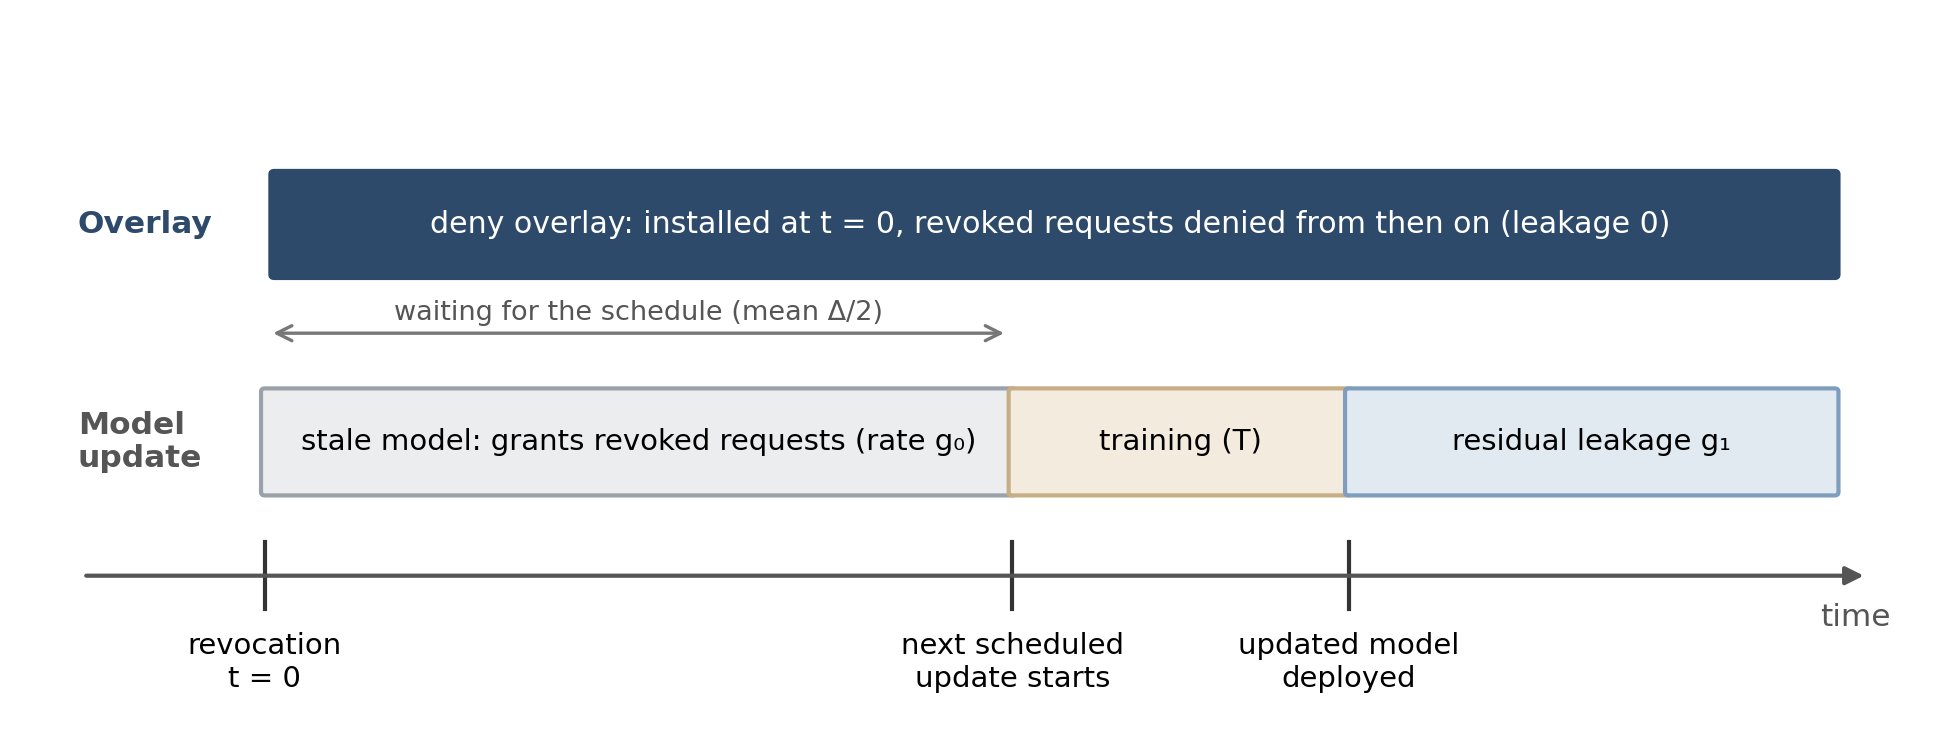

fig3_leakage.png


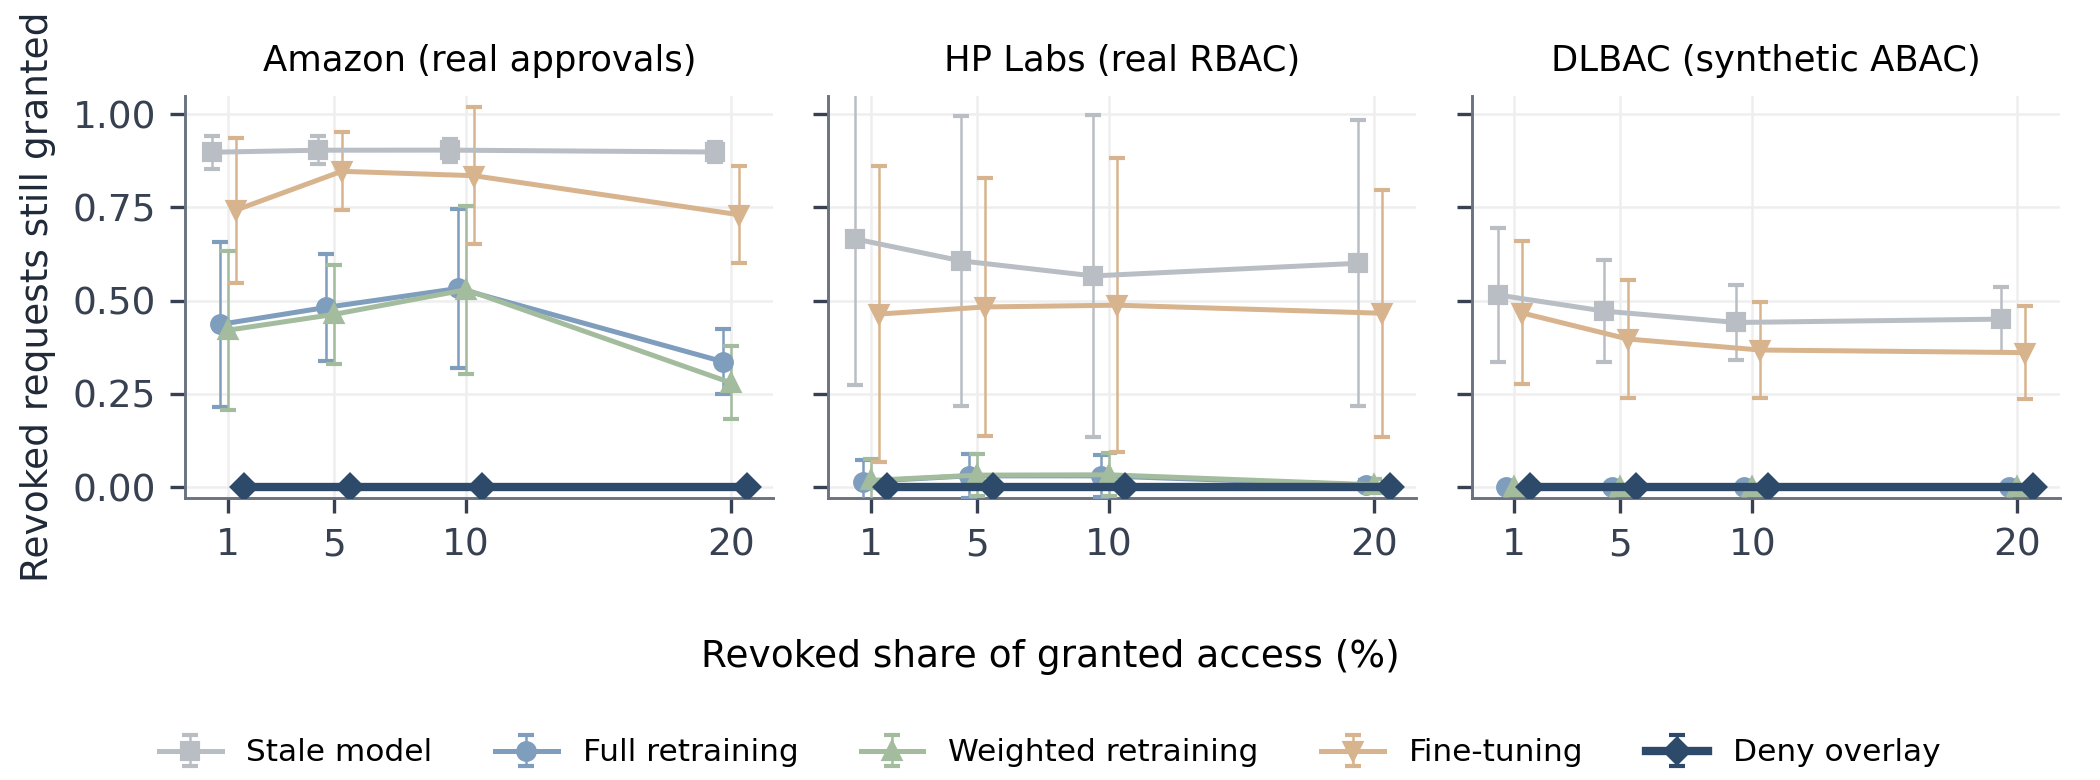

fig4_seen_unseen.png


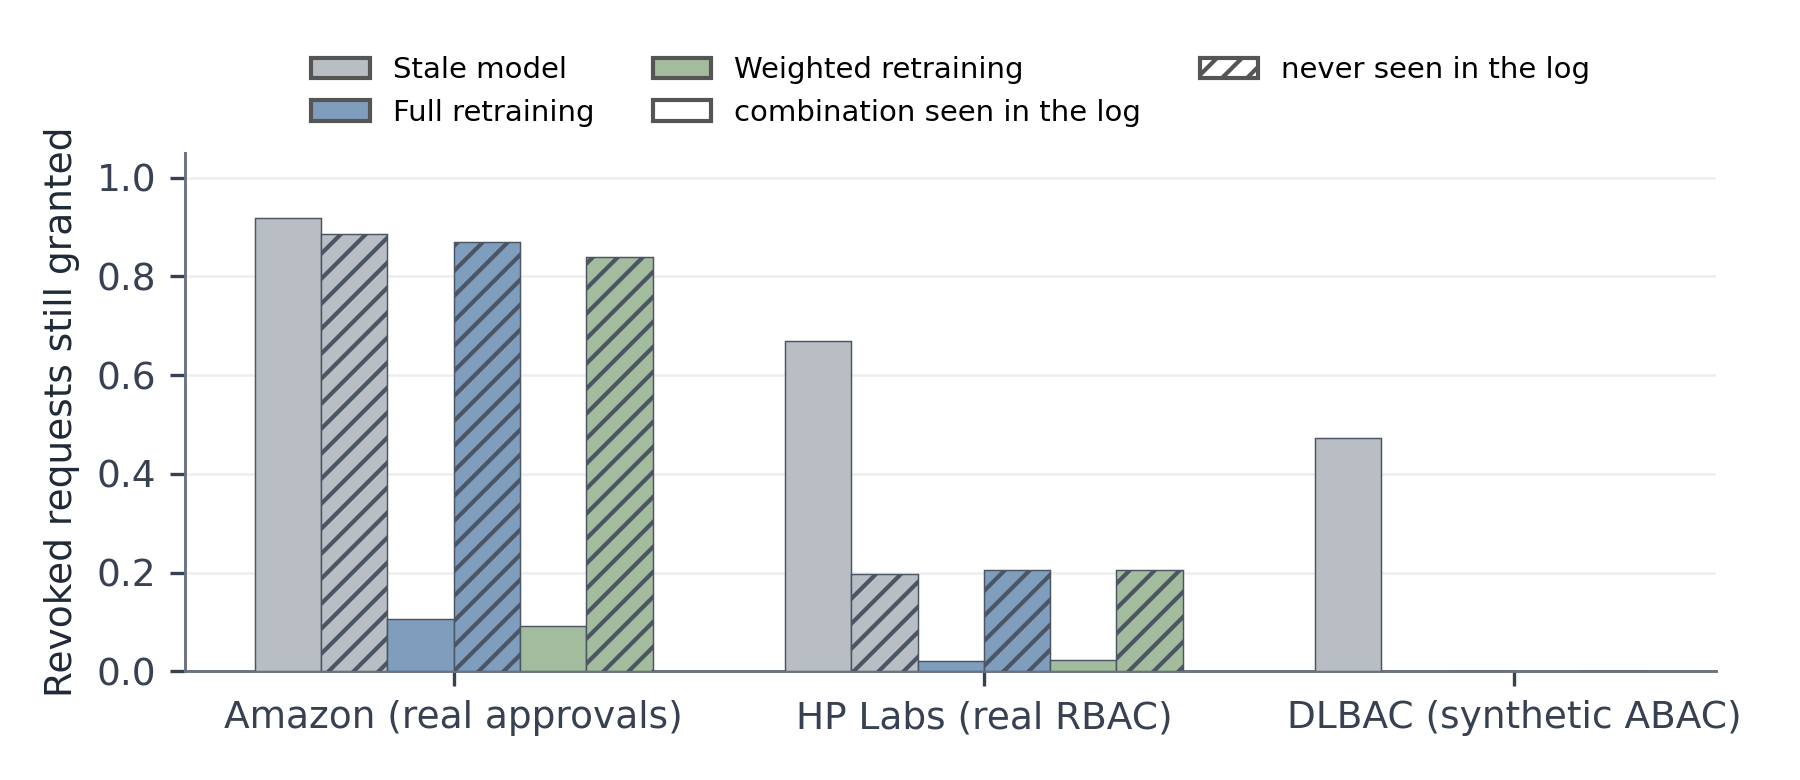

fig5_collateral.png


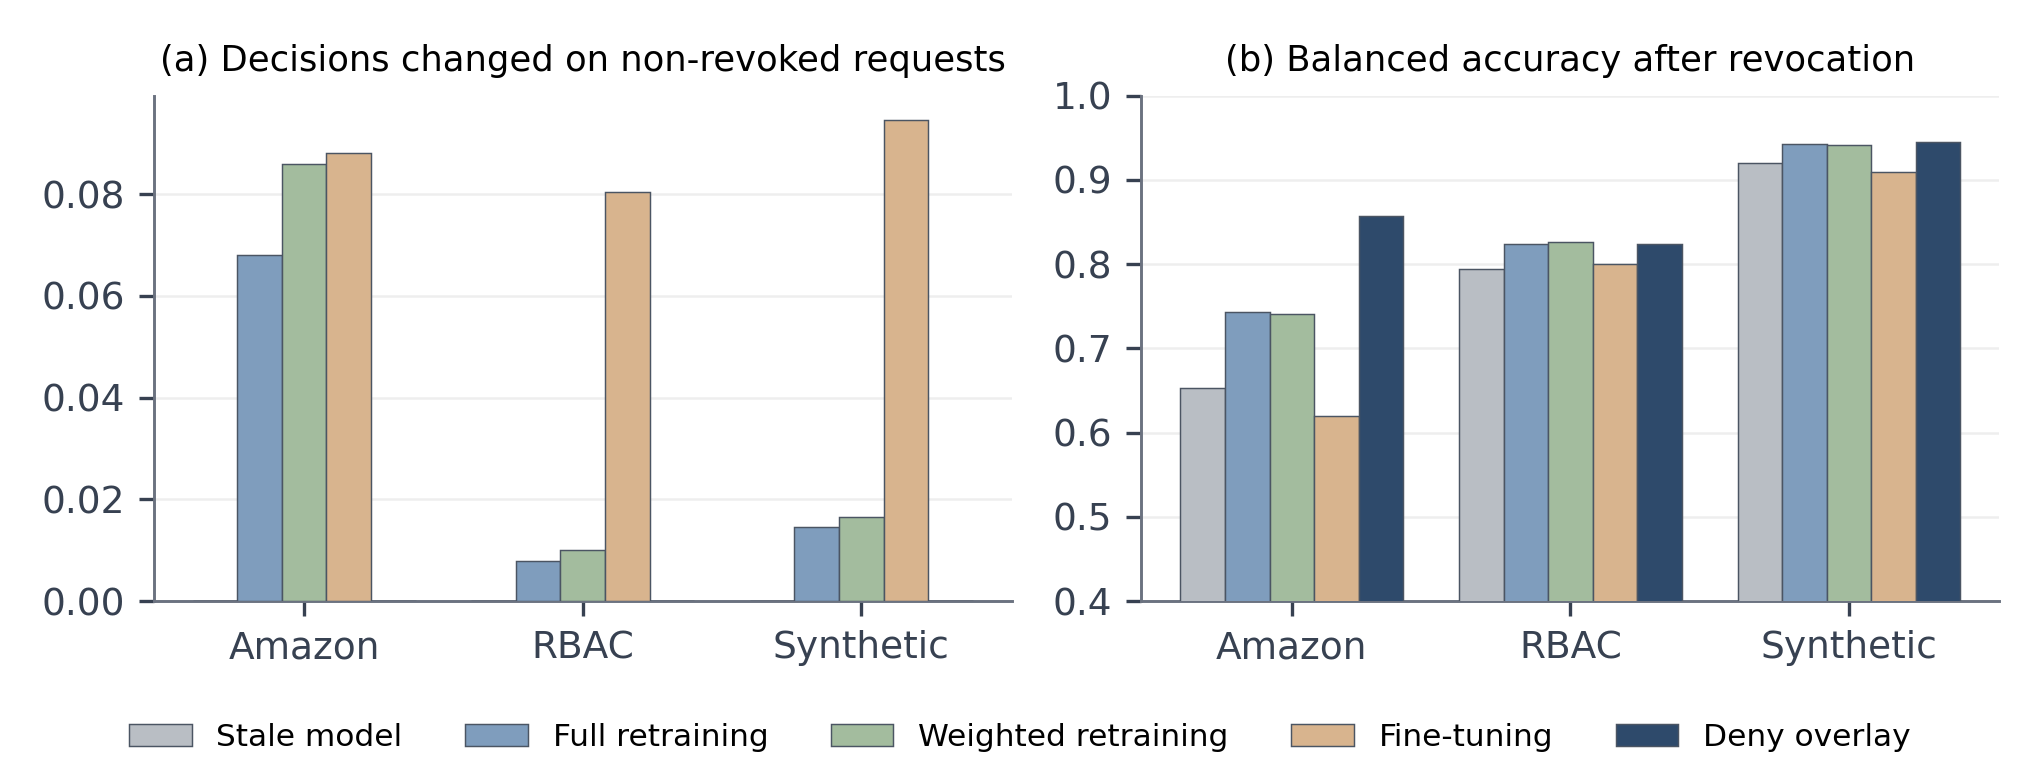

fig6_window.png


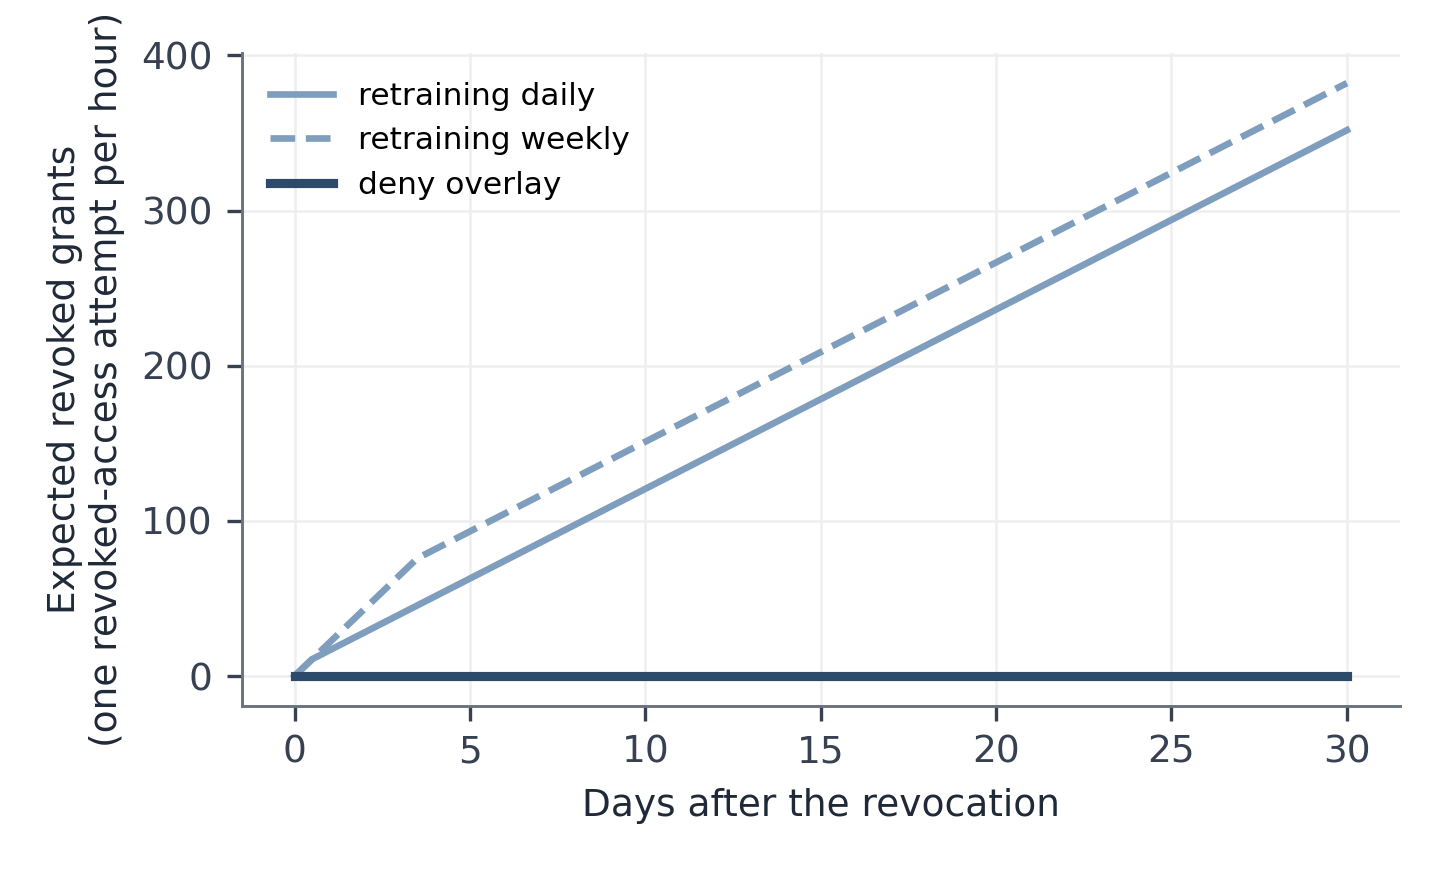

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import analysis2, shutil, pandas as pd
from IPython.display import Image, display
S = analysis2.main("results")
m = pd.read_csv("results/tables/summary_by_family_fraction_remedy.csv")
cols = ["kind", "fraction", "remedy", "leak", "leak_sd", "seen", "leak_seen", "leak_unseen", "changed_unrevoked", "d_frr", "far_orig", "ba", "update_s"]
lines = ["Table S1 / Table 3 / Fig. 2-4 values (mean over splits):", m[cols].round(4).to_string(index=False), "",
         "Table S2 (Wilcoxon signed-rank, Holm-corrected within family and revocation size):", pd.read_csv("results/tables/wilcoxon_tests.csv").to_string(index=False), "",
         "Text values:"] + [f"{k}: {S[k]}" for k in ("n_units", "units_x_fractions", "revoked_requests_total", "seen_fraction", "retrain_unseen_share",
         "retrain_update_s_median", "weighted_update_s_median", "finetune_update_s_median", "overlay_update_ms_max", "overlay_max_leak", "overlay_max_churn", "window")]
txt = "\n".join(lines); print(txt); Path("results/paper_numbers.txt").write_text(txt)
for f in sorted(Path("results/figures").glob("fig*.png")):
    print(f.name); display(Image(filename=str(f), width=620))
shutil.make_archive("revocation_results", "zip", "results")
if IN_COLAB:
    from google.colab import files; files.download("revocation_results.zip")